In [1]:
import numpy as np
import scanpy as sc
import rapids_singlecell as rsc
from matplotlib import pyplot as plt
import seaborn as sns
import pandas as pd
from tqdm import tqdm

sc.set_figure_params(frameon=False, dpi=80, fontsize=12)

from scatlastb_utils.io import read_anndata, write_zarr
from scatlastb_utils.pipeline.misc import dask_compute

/hpc/scratch/project.hca_integration/miniforge3/envs/rapids_singlecell/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound
<frozen importlib._bootstrap_external>:1241: FutureWarning: The cuda.cudart module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.runtime module instead.
<frozen importlib._bootstrap_external>:1241: FutureWarning: The cuda.cuda module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.driver module instead.
/hpc/scratch/project.hca_integration/miniforge3/envs/rapids_singlecell/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jup

# Read data

## Read disease metadata

In [2]:
disease_df = pd.read_excel(
    '/home/michaela.mueller/workspace/immune-v1-scripts/data/metadata/input/tier_2/healthy_covid_meta.xlsx',
)
disease_df = disease_df.drop_duplicates('sample')

## Read pseudobulks

In [3]:
adata_pb = read_anndata(
    'data/pipeline/feature_selection/HICA_CXG/sample_representation/dataset~predict_lineage/'
    'file_id~merge:predict_lineage/input_type~feature/method~pseudobulk--hyperparams~None'
    '--var_mask~None--use_rep~layers/counts.zarr'
)

dask: False, backed: False
Read slot "X", store as "X"...
Read slot "layers", store as "layers"...
Read slot "obs", store as "obs"...
Read slot "obsm", store as "obsm"...


Read obsm slots as_dask=False: 100%|██████████| 2/2 [00:00<00:00, 26.57it/s]

Read slot "obsp", store as "obsp"...



Read obsp slots as_dask=False: 100%|██████████| 2/2 [00:00<00:00, 16.51it/s]

Read slot "uns", store as "uns"...



Read uns slots as_dask=False: 100%|██████████| 6/6 [00:00<00:00, 71.71it/s]

Read slot "var", store as "var"...
Read slot "varm", store as "varm"...
Read slot "varp", store as "varp"...
shape: (94475, 16007)


### Wrangle sample IDs

In [4]:
adata_pb.obs['sample'] = adata_pb.obs['sample'].astype(str)

In [5]:
mask = adata_pb.obs['study'] == "Yazar2022_cxg"
adata_pb.obs.loc[mask, 'sample'] = adata_pb.obs.loc[mask, 'sample'].str.split('-').str[0]
mask = disease_df['study'] == "Yazar2022"
disease_df.loc[mask, 'sample'] = disease_df.loc[mask, 'sample_id']

In [6]:
mask = adata_pb.obs['study'] == "Yoshida2022_cxg"
adata_pb.obs.loc[mask, 'sample'] = adata_pb.obs.loc[mask, 'donor_id']

In [7]:
mask = adata_pb.obs['study'] == "VentoTormo_cxg"
adata_pb.obs.loc[mask, 'sample'] = adata_pb.obs.loc[mask, 'donor_id']

### Merge age metadata

In [8]:
columns = ['sample', 'Age (in years)'] #, 'disease_status']

In [10]:
adata_pb.obs = adata_pb.obs.merge(
    disease_df[columns],
    on='sample',
    how='left',
)

In [9]:
colors=[
    'celltypist_Healthy_COVID19_PBMC:majority_voting',
    'lineage',
    'n_agg',
    'study',
    'sex',
]

... storing 'sample' as categorical
... storing 'Age (in years)' as categorical


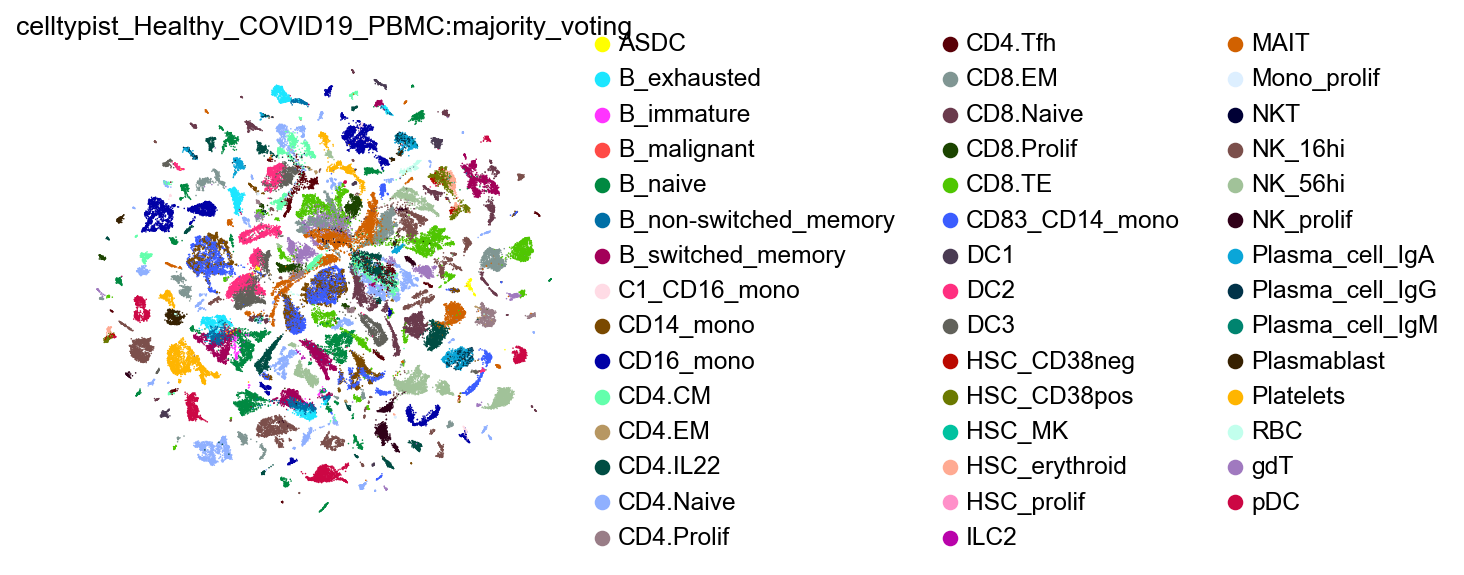

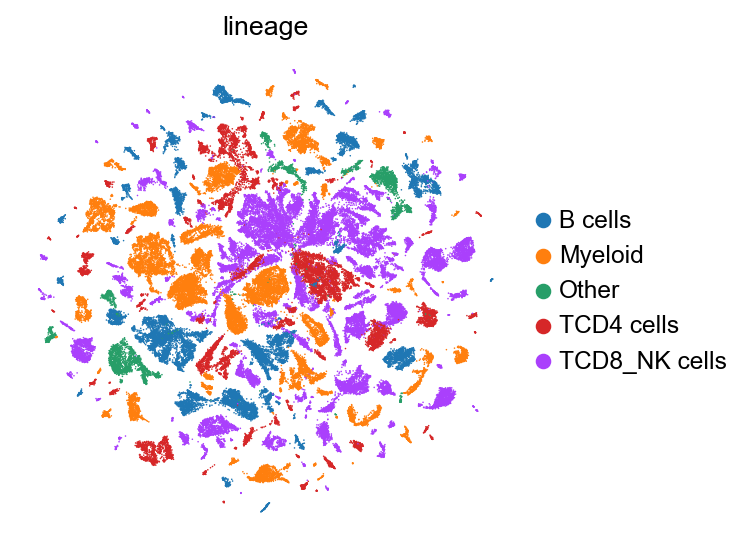

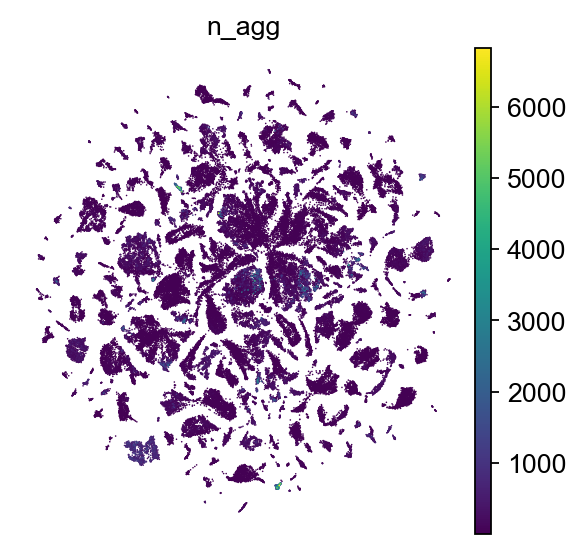

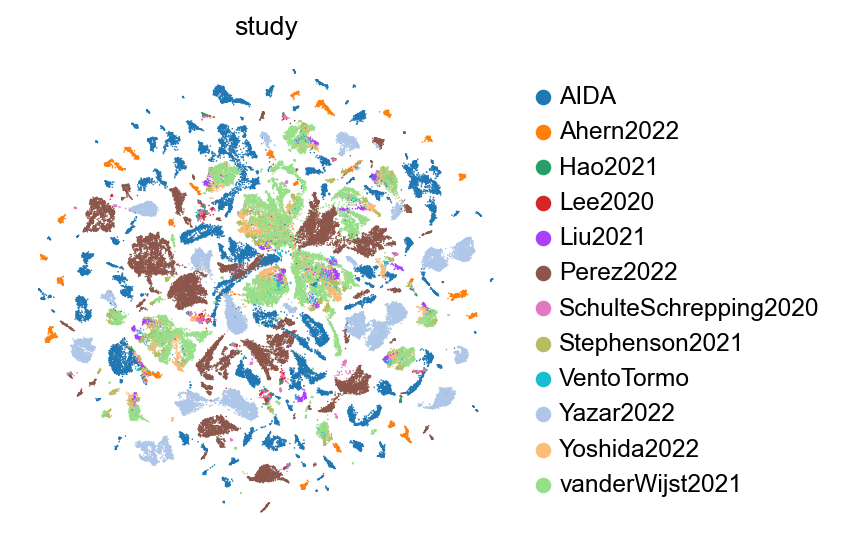

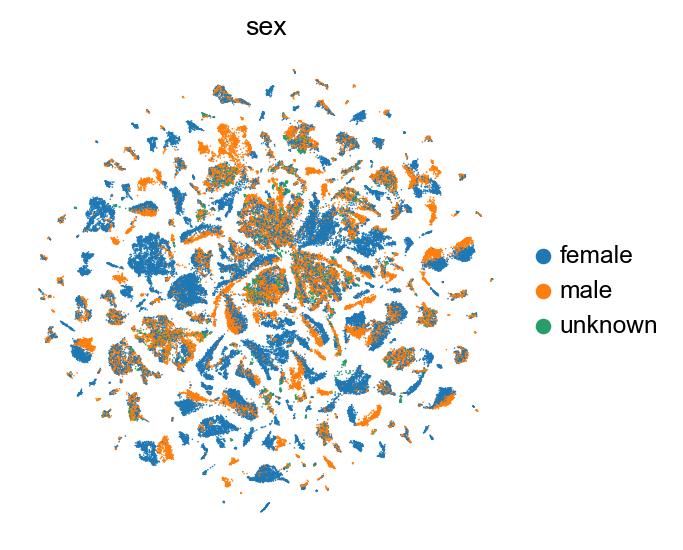

In [11]:
for color in colors:
    sc.pl.umap(
        adata_pb,
        color=color,
        ncols=1,
        size=2,
    )

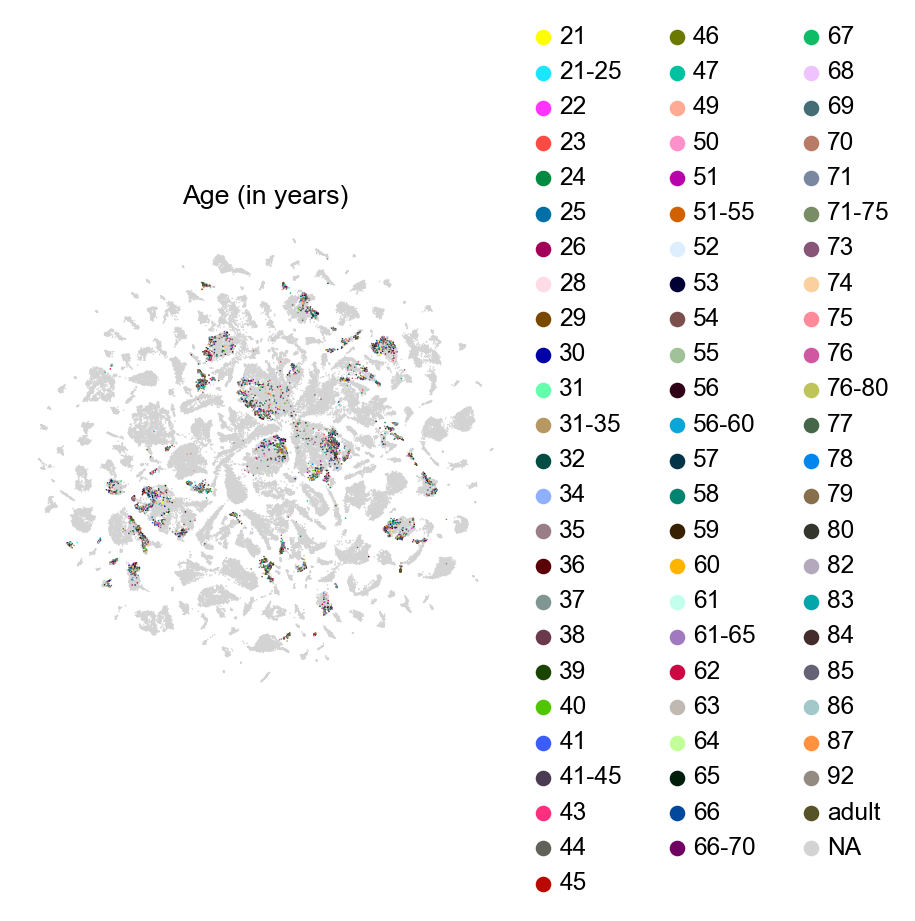

In [12]:
for color in ['Age (in years)']: #, 'disease_status']:
    sc.pl.umap(
        adata_pb,
        color=color,
        ncols=1,
        size=2,
    )

In [13]:
adata_pb.write_h5ad('data/output/export/hica_cxg_pseudobulk.h5ad', compression='lzf')

## Read hyperparameters

In [2]:
hyperparams = pd.read_table('data/pipeline/feature_selection/HICA_CXG/clustering/input_files.tsv')

In [3]:
hyperparams = hyperparams.query('dataset == "global"').copy()
hyperparams['integration'] = hyperparams['file_id'].str.split('--').str[1]
hyperparams['hyperparams'] = hyperparams['file_path'].str.split('var_mask~').str[1]

In [4]:
hyperparams

,dataset,file_id,file_path,integration,hyperparams
82,global,integration:preprocessing:All--integration=429...,data/pipeline/feature_selection/HICA_CXG/integ...,integration=429013bad9,extra_hvgs--batch_key=library_id--n_top_genes=...
83,global,integration:preprocessing:All--integration=b6d...,data/pipeline/feature_selection/HICA_CXG/integ...,integration=b6db15edb2,highly_variable/method~unintegrated--hyperpara...
84,global,integration:preprocessing:All--integration=e99...,data/pipeline/feature_selection/HICA_CXG/integ...,integration=e99de4b0f4,extra_hvgs--batch_key=library_id--n_top_genes=...
85,global,integration:preprocessing:All--integration=739...,data/pipeline/feature_selection/HICA_CXG/integ...,integration=739c89cb94,extra_hvgs--batch_key=library_id--n_top_genes=...
86,global,integration:preprocessing:All--integration=8db...,data/pipeline/feature_selection/HICA_CXG/integ...,integration=8db25de1ea,highly_variable/method~harmony_pytorch--hyperp...
87,global,integration:preprocessing:All--integration=8e0...,data/pipeline/feature_selection/HICA_CXG/integ...,integration=8e0d2946c2,highly_variable/method~harmony_pytorch--hyperp...
88,global,integration:preprocessing:All--integration=351...,data/pipeline/feature_selection/HICA_CXG/integ...,integration=3517ff5245,extra_hvgs--batch_key=library_id--n_top_genes=...
89,global,integration:preprocessing:All--integration=d66...,data/pipeline/feature_selection/HICA_CXG/integ...,integration=d66e3b5375,extra_hvgs--batch_key=library_id--n_top_genes=...
90,global,integration:preprocessing:All--integration=dcf...,data/pipeline/feature_selection/HICA_CXG/integ...,integration=dcf9672da4,highly_variable/method~scvi--hyperparams~afa82...
91,global,integration:preprocessing:All--integration=511...,data/pipeline/feature_selection/HICA_CXG/integ...,integration=51114673bc,highly_variable/method~scvi--hyperparams~67687...


## Read all cells

In [5]:
file_path = 'data/pipeline/feature_selection/HICA_CXG/majority_voting/dataset~global/file_id~collect:global.zarr'

In [6]:
select_keys = hyperparams.query('hyperparams.str.contains("extra_hvgs")')['integration'].values

In [7]:
adata = read_anndata(
    file_path,
    dask=True,
    backed=True,
    layers='layers',
    obs='obs',
    var='var',
    obsm='obsm',
    dask_slots=['X', 'layers', 'obsp', 'obsm'],
    uns='uns',
    select_keys=select_keys,
)

dask: True, backed: True
chunks: (200000, -1)
Read slot "layers", store as "layers"...


Read layers slots as_dask=True: 100%|██████████| 2/2 [00:00<00:00, 53.76it/s]

Read slot "obs", store as "obs"...


Read slot "var", store as "var"...
Read slot "obsm", store as "obsm"...


Read obsm slots as_dask=True: 100%|██████████| 28/28 [00:53<00:00,  1.89s/it]

Read slot "uns", store as "uns"...



Read uns slots as_dask=False: 100%|██████████| 146/146 [00:01<00:00, 115.21it/s]


shape: (7066816, 16007)


# Export data

In [11]:
output_dir = 'data/output/export'
file_name = 'hica_global_cxg.zarr'

In [20]:
hyperparams.to_csv(f'{output_dir}/hica_global_cxg_hyperparams.csv', index=False, sep=';')

In [12]:
%%time
write_zarr(adata, f'{output_dir}/{file_name}')

CPU times: user 7min 7s, sys: 2min 31s, total: 9min 39s
Wall time: 11min 42s


In [13]:
!du -hs {output_dir}/{file_name}

75G	data/output/export/hica_global_cxg.zarr


In [14]:
!du -hd1 {output_dir}/{file_name} | sort -h

12K	data/output/export/hica_global_cxg.zarr/obsp
12K	data/output/export/hica_global_cxg.zarr/varm
12K	data/output/export/hica_global_cxg.zarr/varp
400K	data/output/export/hica_global_cxg.zarr/var
5.3M	data/output/export/hica_global_cxg.zarr/uns
936M	data/output/export/hica_global_cxg.zarr/obs
21G	data/output/export/hica_global_cxg.zarr/obsm
55G	data/output/export/hica_global_cxg.zarr/layers
77G	data/output/export/hica_global_cxg.zarr


In [18]:
%%time
!cd {output_dir} && tar cf - {file_name} | lz4 -f -9 - {file_name}.tar.lz4

Compressed 82181468160 bytes into 73059609207 bytes ==> 88.90%                 
CPU times: user 12.5 s, sys: 2.08 s, total: 14.6 s
Wall time: 45min 17s


In [22]:
ll -h {output_dir} | sort -h

drwxr-xr-x 10 michaela.mueller 4.0K Nov 18 01:46 hlca_qc.zarr/
drwxr-xr-x 10 michaela.mueller 4.0K Nov 18 03:46 hica_global_cxg.zarr/
drwxr-xr-x 11 michaela.mueller 4.0K Nov 12 07:39 hica_global.zarr/
drwxr-xr-x 11 michaela.mueller 4.0K Nov 13 01:49 hica_dcs.zarr/
-rw-r--r--  1 michaela.mueller 1.2G Nov 13 01:50 hica_dcs.zarr.tar.lz4
-rw-r--r--  1 michaela.mueller 2.8K Nov 13 01:50 hica_DC_hyperparams.csv
-rw-r--r--  1 michaela.mueller 3.4K Nov 12 07:24 hica_global_hyperparams.csv
-rw-r--r--  1 michaela.mueller 3.6G Nov 10 03:59 hica_cxg_pseudobulk.h5ad
-rw-r--r--  1 michaela.mueller 5.9K Nov 18 04:33 hica_global_cxg_hyperparams.csv
-rw-r--r--  1 michaela.mueller 6.2G Nov 18 01:51 hlca_qc.zarr.tar.lz4
-rw-r--r--  1 michaela.mueller  69G Nov 18 04:33 hica_global_cxg.zarr.tar.lz4
-rw-rw-r--  1 michaela.mueller  67G Nov 12 08:16 hica_global.zarr.tar.lz4
total 146G


In [26]:
!echo rclone copy -P {output_dir}/{file_name}.tar.lz4 onedrive:scAtlasTb/HICA/CXG

rclone copy -P data/output/export/hica_global_cxg.zarr.tar.lz4 onedrive:scAtlasTb/HICA/CXG


# Plot UMAPs

In [60]:
integration = 'f4ab30fa45' # DRVI
integration = '3517ff5245' # scVI 128

In [62]:
adata.uns[f'integration--label_transfer:clustering:integration:preprocessing:All--integration={integration}'].get('hyperparams')

{'dispersion': 'gene-batch',
 'dropout_rate': 0.2,
 'early_stopping': True,
 'max_epochs': 50,
 'n_hidden': 128,
 'n_latent': 30,
 'n_layers': 2,
 'use_observed_lib_size': True}

In [59]:
hyperparams.query('hyperparams.str.contains("scvi")')[['integration', 'hyperparams']].to_dict('list')

{'integration': ['integration=3517ff5245',
  'integration=d66e3b5375',
  'integration=dcf9672da4',
  'integration=51114673bc'],
 'hyperparams': ['extra_hvgs--batch_key=library_id--n_top_genes=3000/method~scvi--hyperparams~afa8217de2--label~None--output_type~embed.zarr',
  'extra_hvgs--batch_key=library_id--n_top_genes=3000/method~scvi--hyperparams~676871383b--label~None--output_type~embed.zarr',
  'highly_variable/method~scvi--hyperparams~afa8217de2--label~None--output_type~embed.zarr',
  'highly_variable/method~scvi--hyperparams~676871383b--label~None--output_type~embed.zarr']}

In [63]:
hyperparams.query(f'integration == "integration={integration}"')['hyperparams'].tolist()

['extra_hvgs--batch_key=library_id--n_top_genes=3000/method~scvi--hyperparams~afa8217de2--label~None--output_type~embed.zarr']

In [64]:
adata.obsm[f'X_umap--label_transfer:clustering:integration:preprocessing:All--integration={integration}'] = \
    adata.obsm[f'X_umap--label_transfer:clustering:integration:preprocessing:All--integration={integration}'].compute()

In [65]:
colors =[
    'celltypist_Healthy_COVID19_PBMC:majority_voting',
    'celltypist_COVID19_HumanChallenge_Blood:majority_voting',
    'lineage',
    'sex',
    'development_stage_ontology_term_id',
    'study',
    # 'Age (in years)',
    'disease',
]

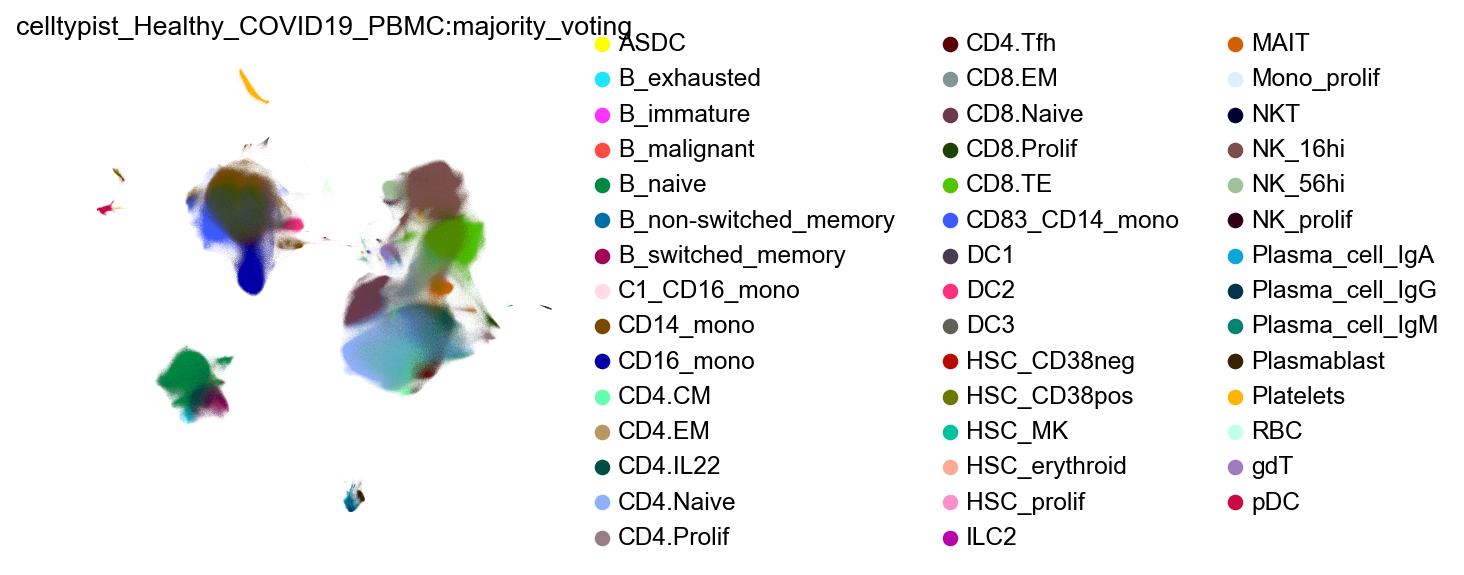

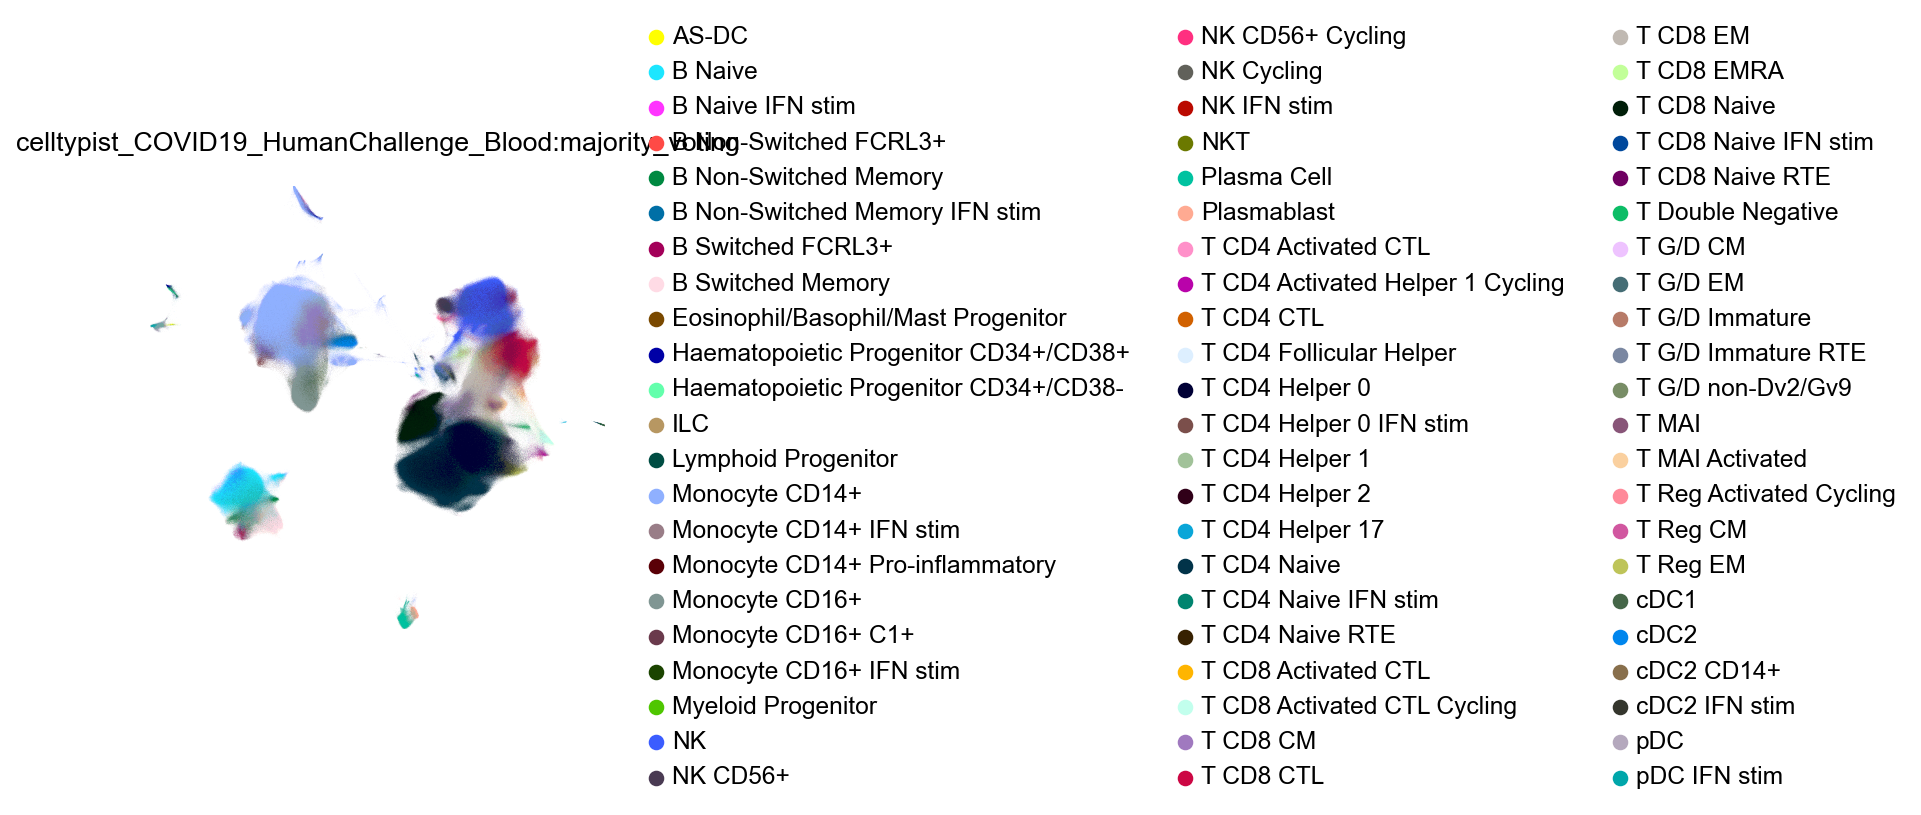

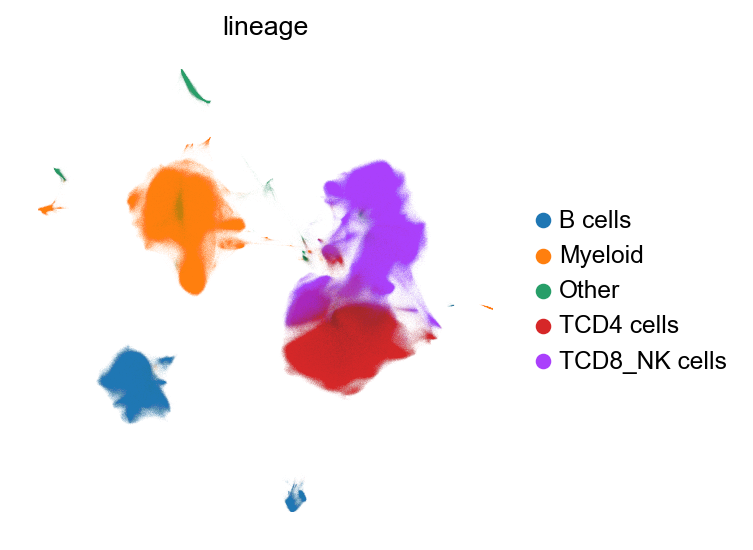

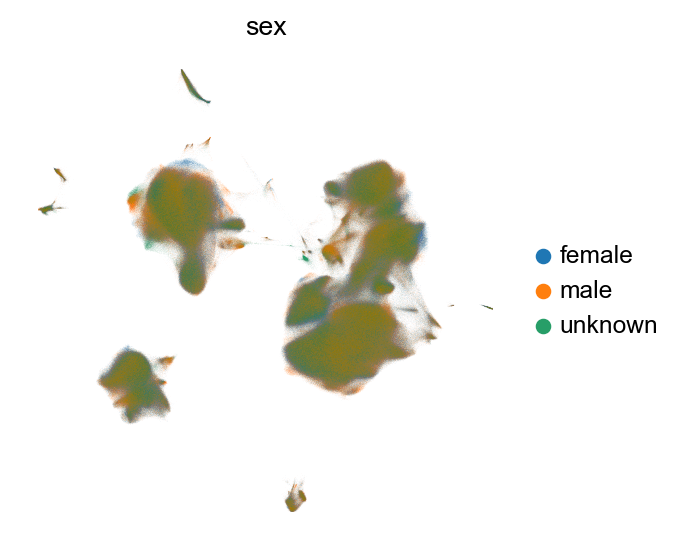

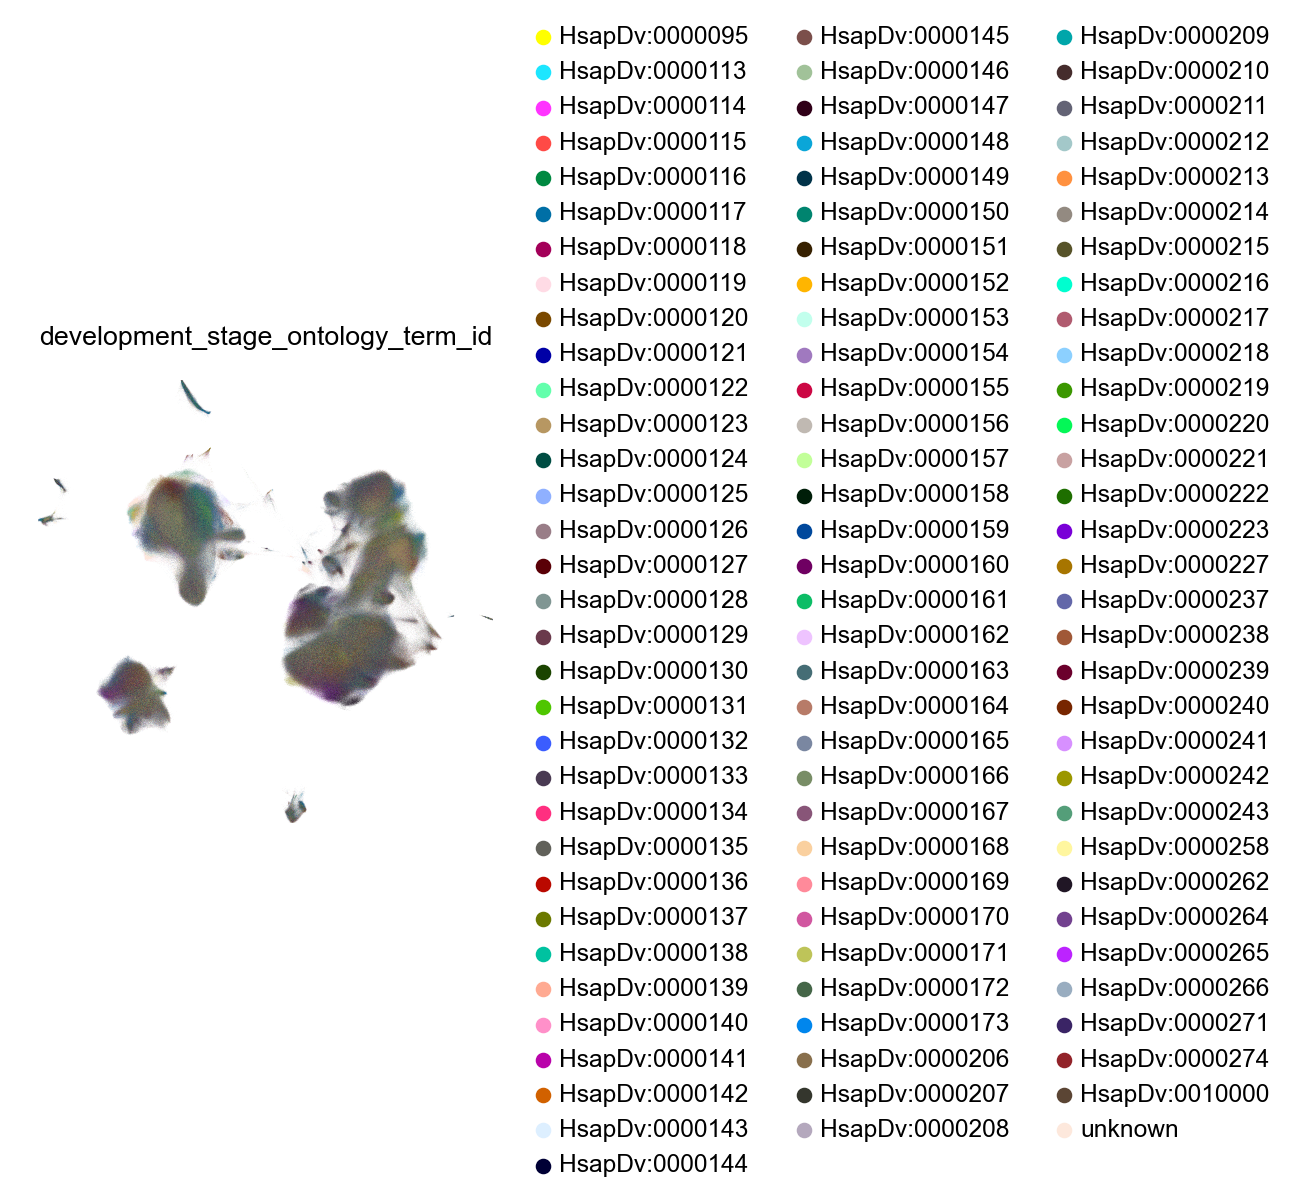

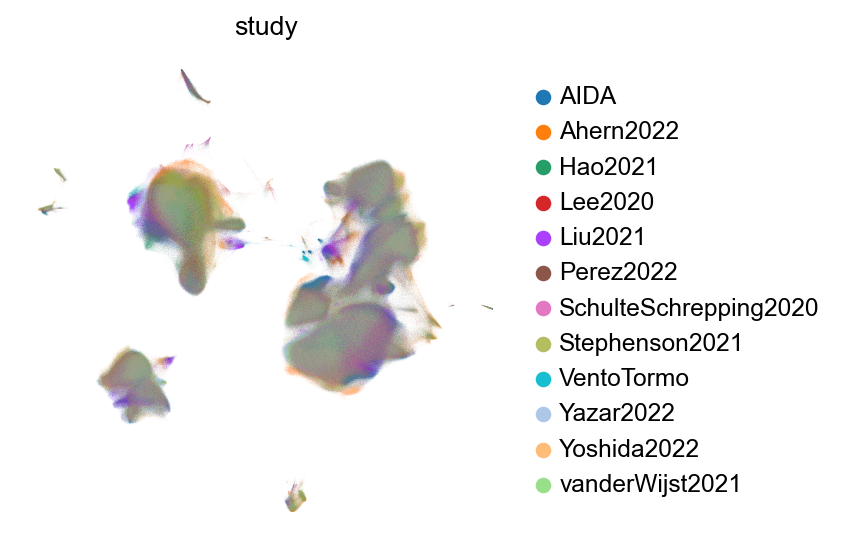

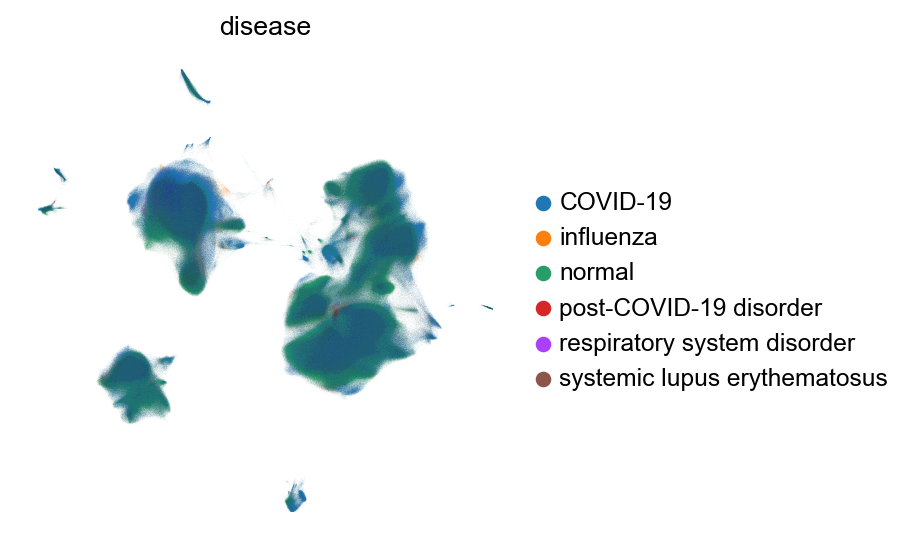

CPU times: user 3min 53s, sys: 1.26 s, total: 3min 55s
Wall time: 3min 55s


In [66]:
%%time
for color in colors:
    sc.pl.embedding(
        adata,
        basis=f'X_umap--label_transfer:clustering:integration:preprocessing:All--integration={integration}',
        color=color,
        ncols=1,
    )

In [68]:
genes = [
    'IFIT1',
    'IFIT2',
    'IFIT3',
    'RSAD2',
    'OAS1',
    'MX1',
    'TNFSF10',
    'IL1RN',
]

In [69]:
adata = adata[:, adata.var['feature_name'].isin(genes)].copy()

In [70]:
adata = dask_compute(adata, layers='X')

Apply function compute_layer to X...


In [71]:
adata.var_names = adata.var['feature_name']

CPU times: user 10.4 ms, sys: 71 μs, total: 10.4 ms
Wall time: 10.1 ms


TypeError: 'NoneType' object is not subscriptable

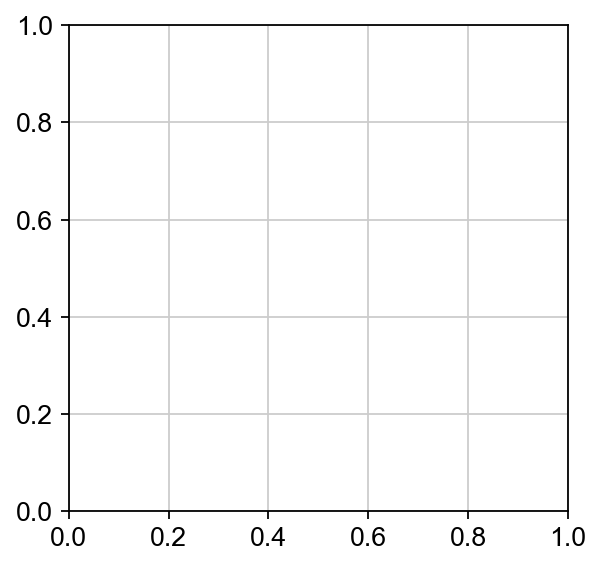

In [73]:
%%time
for gene in genes:
    sc.pl.embedding(
        adata,
        basis=f'X_umap--label_transfer:clustering:integration:preprocessing:All--integration={integration}',
        color=gene,
        ncols=1,
        size=2,
    )